# 01 · EDA, Stationarity and ARMA Identification (Lectures 1–20)

**Data:** `data/processed/yellowstone_master_ts_flagged.csv` (annual, 1984–2025).
**Target:** northern Yellowstone elk counts.

Sections
1. Exploratory plots (imputed values marked)
2. Trend estimation and smoothing
3. Stationarity tests (ADF + KPSS)
4. ACF / PACF of the stationary elk series
5. Did the elk trend change at 1995? (regression with a dummy variable)
6. ARMA identification, Yule–Walker and parameter redundancy
7. Residual diagnostics

Only methods from lectures 1–20 are used. Information criteria (AIC/BIC) are added after midsem with the Box–Jenkins material.

Figures are saved to `reports/figures/`.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(ROOT / "data" / "processed" / "yellowstone_master_ts_flagged.csv", index_col="Year")
VARS = ["Elk_Count", "Wolf_Northern", "Bison_Count", "NDVI", "Precip_Annual", "PDSI_Annual"]
LABELS = {"Elk_Count": "Elk (count)", "Wolf_Northern": "Wolves, northern range",
          "Bison_Count": "Bison (northern herd)", "NDVI": "Summer NDVI",
          "Precip_Annual": "Precipitation (mm, calendar year)", "PDSI_Annual": "PDSI (drought index)"}
REINTRO = 1995
df[VARS].describe().round(2)

,Elk_Count,Wolf_Northern,Bison_Count,NDVI,Precip_Annual,PDSI_Annual
count,42.00,42.00,42.00,42.00,42.00,42.00
mean,10237.67,40.45,1957.83,0.52,571.05,-0.36
std,4930.41,29.57,1441.01,0.04,67.85,2.22
min,3915.00,0.00,432.00,0.41,426.35,-4.85
25%,5844.00,5.25,808.25,0.50,525.14,-2.08
50%,8851.50,40.50,1258.50,0.51,575.09,-0.42
75%,14751.75,57.75,3423.00,0.55,606.38,1.41
max,19048.00,98.00,5300.00,0.59,696.16,3.53


## 1. Exploratory plots
Hollow red points are imputed values (see the `*_source` columns). Dashed line = 1995 wolf reintroduction.

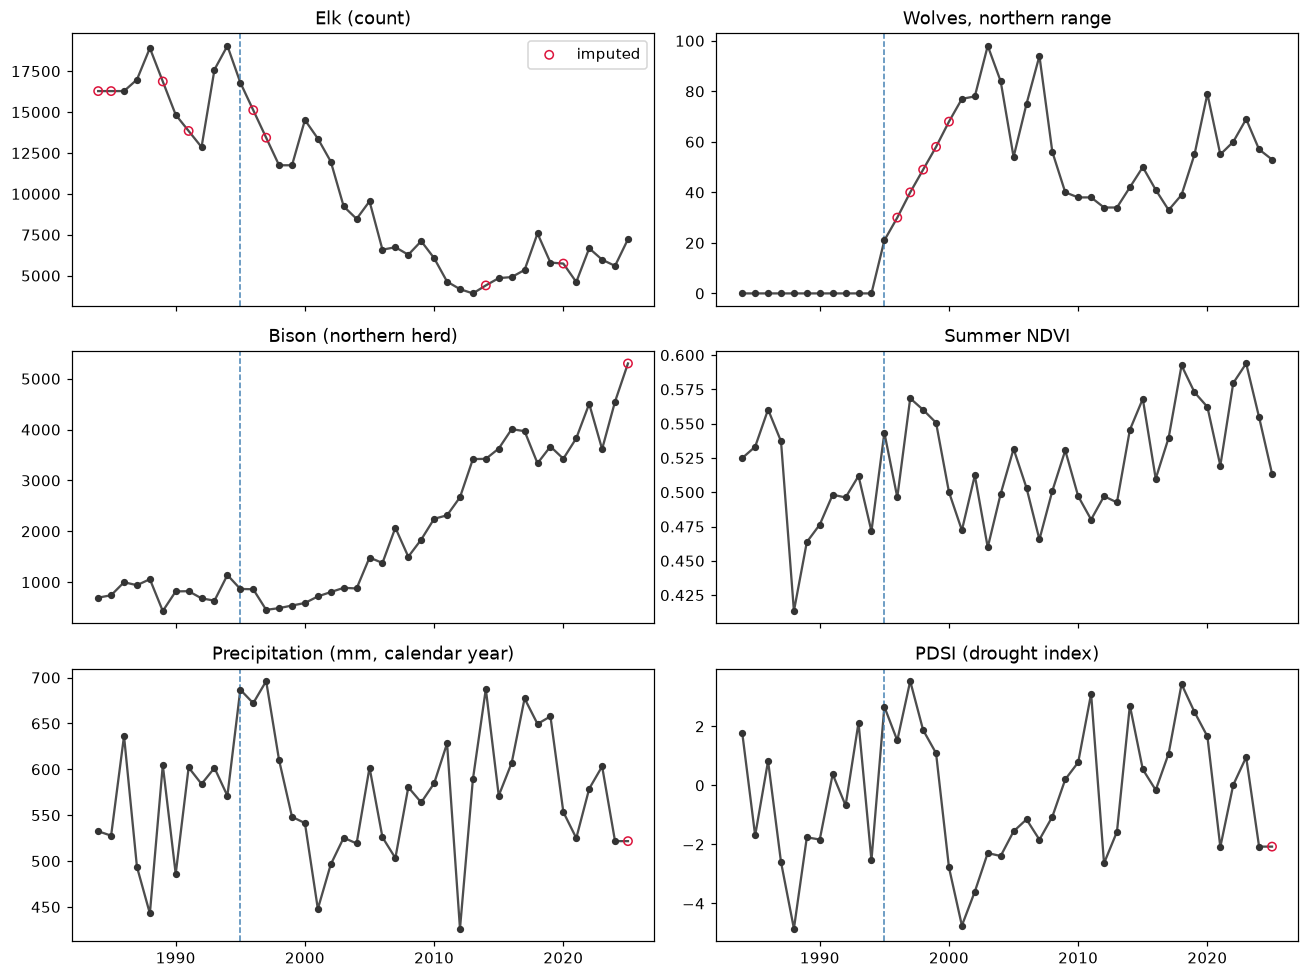

In [2]:
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
for ax, col in zip(axes.flat, VARS):
    imp = df[f"{col}_imputed"] == 1
    ax.plot(df.index, df[col], color="0.3", lw=1.5)
    ax.scatter(df.index[~imp], df.loc[~imp, col], s=14, color="0.2", zorder=3)
    ax.scatter(df.index[imp], df.loc[imp, col], s=30, facecolors="none", edgecolors="crimson", zorder=4, label="imputed")
    ax.axvline(REINTRO, ls="--", color="steelblue", lw=1)
    ax.set_title(LABELS[col])
axes[0, 0].legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIG / "01_all_series.png", dpi=200)

### Correlations
Correlations between **levels** of trending series can be spurious (two series that both trend look related).
Correlations between **first differences** are the more honest check.

In [3]:
levels = df[VARS].corr().round(2)
diffs = df[VARS].diff().dropna().corr().round(2)
print("Correlation with elk — levels vs first differences")
pd.DataFrame({"levels": levels["Elk_Count"], "differences": diffs["Elk_Count"]}).drop("Elk_Count")

Correlation with elk — levels vs first differences


,levels,differences
Wolf_Northern,-0.61,-0.21
Bison_Count,-0.77,0.18
NDVI,-0.29,-0.05
Precip_Annual,-0.08,-0.04
PDSI_Annual,-0.16,-0.10


## 2. Trend estimation and smoothing (elk)

,model,RSS,adj_R2,highest-order term p
0,linear,2.032067e+08,0.791,0.000
1,quadratic,1.717695e+08,0.819,0.011
2,cubic,8.844658e+07,0.904,0.000


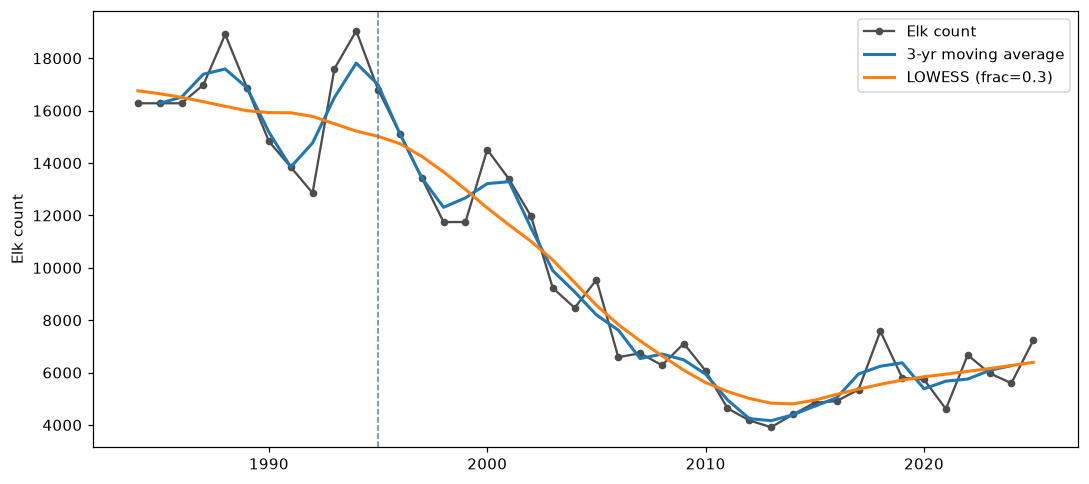

In [4]:
elk = df["Elk_Count"]
t = np.arange(len(elk))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(elk.index, elk, "o-", color="0.3", ms=4, label="Elk count")
ax.plot(elk.index, elk.rolling(3, center=True).mean(), lw=2, label="3-yr moving average")
low = sm.nonparametric.lowess(elk.values, elk.index.values, frac=0.3)
ax.plot(low[:, 0], low[:, 1], lw=2, label="LOWESS (frac=0.3)")
ax.axvline(REINTRO, ls="--", color="steelblue", lw=1)
ax.set_ylabel("Elk count"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "02_elk_smoothing.png", dpi=200)

rows = []
for name, deg in [("linear", 1), ("quadratic", 2), ("cubic", 3)]:
    X = sm.add_constant(np.column_stack([t**k for k in range(1, deg + 1)]))
    m = sm.OLS(elk.values, X).fit()
    rows.append({"model": name, "RSS": m.ssr, "adj_R2": m.rsquared_adj,
                 "highest-order term p": m.pvalues[-1]})
pd.DataFrame(rows).round(3)

## 3. Stationarity tests (ADF + KPSS)
- **ADF**: H0 = unit root (non-stationary). p < 0.05 → evidence of stationarity. Run with 0, 1 and 2 lagged differences; counted as rejecting if it rejects at 2 of the 3.
- **KPSS**: H0 = stationary. p < 0.05 → evidence of non-stationarity.

The two tests have opposite null hypotheses, so they are read together:

| ADF | KPSS | Conclusion |
|---|---|---|
| rejects | does not reject | stationary |
| does not reject | rejects | non-stationary |
| both reject / neither rejects | | inconclusive — read the plots |

With n ≈ 42 both tests have limited power. KPSS p-values are reported within 0.01–0.10 (values at the edge mean "≤ 0.01" or "≥ 0.10").

In [5]:
def stationarity(x, name):
    # ADF at fixed lag orders 0, 1, 2 (annual data, n≈42); results that hold across
    # lag choices are more trustworthy than any single run.
    x = pd.Series(x).dropna()
    res = {"series": name, "n": len(x)}
    ps = []
    for lag in (0, 1, 2):
        r = adfuller(x, maxlag=lag, autolag=None)
        res[f"ADF_stat_lag{lag}"] = r[0]; res[f"p_lag{lag}"] = r[1]; ps.append(r[1])
    adf_rejects = sum(p < 0.05 for p in ps) >= 2
    k = kpss(x, regression="c", nlags="auto")
    res["KPSS_stat"] = k[0]; res["KPSS_p"] = k[1]
    kpss_rejects = k[1] < 0.05
    res["ADF says"] = "stationary" if adf_rejects else "unit root"
    res["KPSS says"] = "non-stationary" if kpss_rejects else "stationary"
    res["conclusion"] = ("stationary" if adf_rejects and not kpss_rejects else
                         "non-stationary" if not adf_rejects and kpss_rejects else "inconclusive")
    return res

rows = []
for col in VARS:
    rows.append(stationarity(df[col], f"{col} (level)"))
    rows.append(stationarity(df[col].diff(), f"{col} (1st diff)"))
rows.append(stationarity(np.log(elk), "Elk (log)"))
rows.append(stationarity(np.log(elk).diff(), "Elk (log diff)"))
st = pd.DataFrame(rows).round(3)
st.to_csv(FIG / "03_stationarity.csv", index=False)
st

,series,n,ADF_stat_lag0,p_lag0,ADF_stat_lag1,p_lag1,ADF_stat_lag2,p_lag2,KPSS_stat,KPSS_p,ADF says,KPSS says,conclusion
0,Elk_Count (level),42,-1.306,0.626,-1.384,0.590,-1.253,0.650,0.835,0.010,unit root,non-stationary,non-stationary
1,Elk_Count (1st diff),41,-5.774,0.000,-5.007,0.000,-4.922,0.000,0.135,0.100,stationary,stationary,stationary
2,Wolf_Northern (level),42,-1.738,0.412,-1.829,0.366,-1.472,0.547,0.467,0.049,unit root,non-stationary,non-stationary
3,Wolf_Northern (1st diff),41,-5.980,0.000,-6.259,0.000,-3.148,0.023,0.144,0.100,stationary,stationary,stationary
4,Bison_Count (level),42,0.487,0.984,1.111,0.995,1.363,0.997,0.841,0.010,unit root,non-stationary,non-stationary
5,Bison_Count (1st diff),41,-8.292,0.000,-4.840,0.000,-2.797,0.059,0.360,0.094,stationary,stationary,stationary
6,NDVI (level),42,-3.790,0.003,-3.194,0.020,-2.579,0.097,0.406,0.075,stationary,stationary,stationary
7,NDVI (1st diff),41,-7.997,0.000,-6.288,0.000,-5.682,0.000,0.242,0.100,stationary,stationary,stationary
8,Precip_Annual (level),42,-4.660,0.000,-3.472,0.009,-2.321,0.165,0.101,0.100,stationary,stationary,stationary
9,Precip_Annual (1st diff),41,-9.359,0.000,-7.638,0.000,-4.251,0.001,0.406,0.074,stationary,stationary,stationary


## 4. ACF / PACF of the stationary elk series (log-differences)
With n ≈ 41, only lags up to ~10 are meaningful.

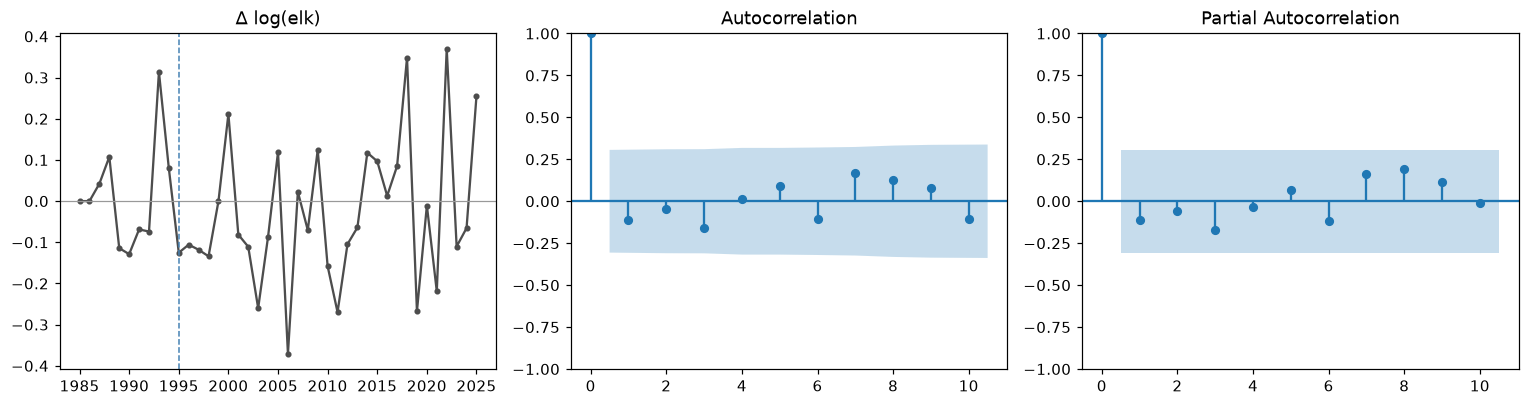

In [6]:
y = np.log(elk).diff().dropna()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].plot(y.index, y, "o-", ms=3, color="0.3"); axes[0].axhline(0, color="0.6", lw=0.8)
axes[0].axvline(REINTRO, ls="--", color="steelblue", lw=1); axes[0].set_title("Δ log(elk)")
plot_acf(y, lags=10, ax=axes[1]); plot_pacf(y, lags=10, ax=axes[2], method="ywm")
fig.tight_layout(); fig.savefig(FIG / "04_elk_acf_pacf.png", dpi=200)

## 5. Did the elk trend change at 1995? (regression with a dummy variable)
Least-squares regression of log(elk) on time, allowing both the level and the slope to change from 1995:

log(elk)_t = b0 + b1·t + b2·D_t + b3·D_t·(t − t_1995) + e_t,   where D_t = 1 from 1995 onward.

- b3 = change in the yearly growth rate after 1995 (the key coefficient)
- b2 = jump in level at 1995
- The joint F-test (b2 = b3 = 0) asks whether the post-1995 terms add anything at all.

In [7]:
ly = np.log(elk)
D = (ly.index >= REINTRO).astype(int)
X = pd.DataFrame({"t": t, "post1995": D, "post1995_x_t": D * (t - t[list(ly.index).index(REINTRO)])}, index=ly.index)
brk = sm.OLS(ly, sm.add_constant(X)).fit()
print(brk.summary().tables[1])
ftest = brk.f_test("post1995 = 0, post1995_x_t = 0")
print()
print(f"Joint F-test (no change at 1995): F = {float(ftest.fvalue):.2f}, p = {float(ftest.pvalue):.4f}")
b1, b3 = brk.params["t"], brk.params["post1995_x_t"]
print(f"Yearly trend in log(elk): before 1995 = {b1:+.3f}, from 1995 = {b1 + b3:+.3f}  (−0.04 ≈ 4% decline per year)")

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            9.7072      0.138     70.108      0.000       9.427       9.987
t               -0.0024      0.023     -0.103      0.919      -0.050       0.045
post1995        -0.2334      0.181     -1.292      0.204      -0.599       0.132
post1995_x_t    -0.0337      0.024     -1.410      0.167      -0.082       0.015

Joint F-test (no change at 1995): F = 1.10, p = 0.3433
Yearly trend in log(elk): before 1995 = -0.002, from 1995 = -0.036  (−0.04 ≈ 4% decline per year)


## 6. ARMA identification on Δ log(elk)
Candidates suggested by the ACF/PACF are fitted and judged on what lectures 15–20 cover:
1. **Are the AR/MA coefficients significant?** (p < 0.05) If not, the term is not needed.
2. **Are the residuals white noise?** (residual ACF inside the bands; Ljung–Box p > 0.05)
3. **Parameter redundancy and invertibility:** in ARMA(1,1), if φ ≈ −θ the AR and MA factors cancel and the model collapses to white noise; if |θ| is close to 1 the model is close to non-invertible and its estimates are unstable.
4. **Parsimony:** among models passing 1–2, choose the simplest.

In [8]:
cands = [(0, 0), (1, 0), (2, 0), (0, 1), (0, 2), (1, 1)]
rows, fits = [], {}
for p_, q_ in cands:
    m = ARIMA(y, order=(p_, 0, q_), trend="c").fit()
    fits[(p_, q_)] = m
    terms = [k for k in m.params.index if k.startswith(("ar.", "ma."))]
    lb = acorr_ljungbox(m.resid, lags=[8]).lb_pvalue.iloc[0]
    rows.append({"model": "white noise" if (p_, q_) == (0, 0) else f"ARMA({p_},{q_})",
                 "coefficients": ", ".join(f"{k}={m.params[k]:.3f} (p={m.pvalues[k]:.2f})" for k in terms) or "—",
                 "all terms significant": all(m.pvalues[k] < 0.05 for k in terms) if terms else True,
                 "residual variance": m.params["sigma2"],
                 "LjungBox_p(lag8)": lb, "white-noise residuals": lb > 0.05})
sel = pd.DataFrame(rows).round(4)
sel.to_csv(FIG / "06_arma_identification.csv", index=False)
sel

,model,coefficients,all terms significant,residual variance,LjungBox_p(lag8),white-noise residuals
0,white noise,—,True,0.0272,0.7470,True
1,"ARMA(1,0)",ar.L1=-0.116 (p=0.53),False,0.0268,0.7467,True
2,"ARMA(2,0)","ar.L1=-0.122 (p=0.51), ar.L2=-0.059 (p=0.82)",False,0.0267,0.7650,True
3,"ARMA(0,1)",ma.L1=-0.140 (p=0.43),False,0.0268,0.7458,True
4,"ARMA(0,2)","ma.L1=-0.155 (p=0.38), ma.L2=-0.088 (p=0.73)",False,0.0265,0.7940,True
5,"ARMA(1,1)","ar.L1=0.841 (p=0.00), ma.L1=-1.000 (p=0.99)",False,0.0250,0.8497,True


In [9]:
phi, theta = fits[(1, 1)].params["ar.L1"], fits[(1, 1)].params["ma.L1"]
print(f"ARMA(1,1): phi = {phi:.3f}, theta = {theta:.3f}, phi + theta = {phi + theta:.3f}")
print("Redundancy: phi + theta close to 0 means (1 - phi B) and (1 + theta B) nearly cancel.")
print(f"Invertibility: |theta| = {abs(theta):.3f}  (must be < 1; values near 1 signal an unstable, over-fitted MA term)")
v0, v11 = fits[(0, 0)].params["sigma2"], fits[(1, 1)].params["sigma2"]
print(f"Residual variance: white noise {v0:.4f} vs ARMA(1,1) {v11:.4f}  ({100*(1-v11/v0):.0f}% lower with 2 extra parameters)")

ARMA(1,1): phi = 0.841, theta = -1.000, phi + theta = -0.159
Redundancy: phi + theta close to 0 means (1 - phi B) and (1 + theta B) nearly cancel.
Invertibility: |theta| = 1.000  (must be < 1; values near 1 signal an unstable, over-fitted MA term)
Residual variance: white noise 0.0272 vs ARMA(1,1) 0.0250  (8% lower with 2 extra parameters)


### Yule–Walker vs maximum likelihood for AR(1)

In [10]:
rho, sigma = sm.regression.yule_walker(y.values - y.mean(), order=1, method="mle")
ml = fits[(1, 0)].params
print(f"AR(1) phi — Yule–Walker: {rho[0]:.3f}   |   MLE: {ml['ar.L1']:.3f}")

AR(1) phi — Yule–Walker: -0.110   |   MLE: -0.116


## 7. Residual diagnostics for the chosen model
Chosen = simplest candidate whose terms are all significant and whose residuals are white noise.

Chosen model: white noise
Shapiro–Wilk normality p = 0.182


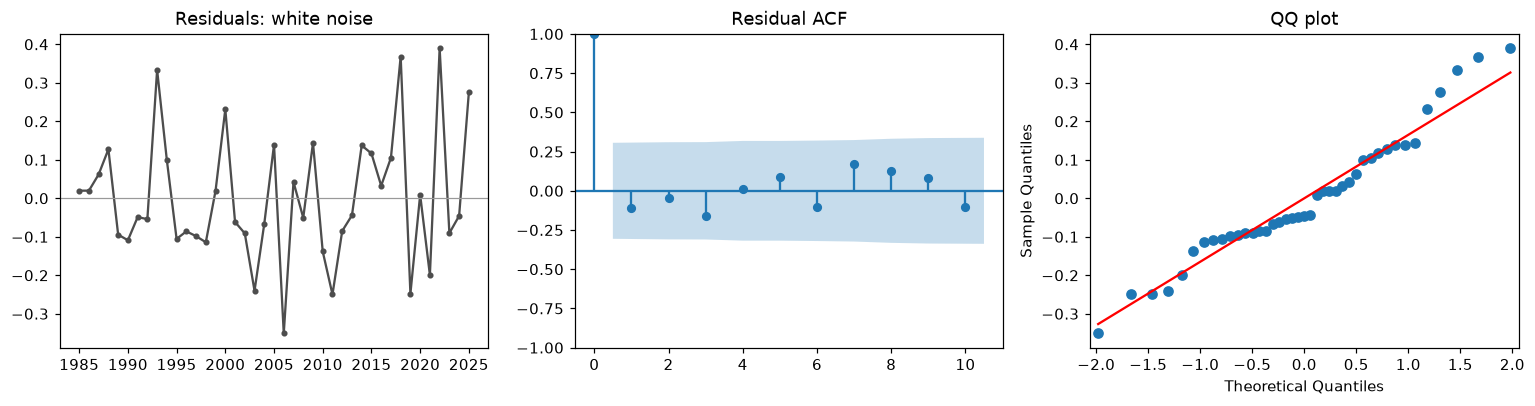

In [11]:
ok = [i for i, r in enumerate(rows) if r["all terms significant"] and r["white-noise residuals"]]
best_key = min((cands[i] for i in ok), key=lambda pq: sum(pq)) if ok else min(fits, key=lambda pq: fits[pq].bic)
if not ok: print("No candidate passes all diagnostics; BIC fallback is provisional.")
chosen = "white noise" if best_key == (0, 0) else f"ARMA{best_key}"
print("Chosen model:", chosen)
best = fits[best_key]
r = best.resid
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].plot(r.index, r, "o-", ms=3, color="0.3"); axes[0].axhline(0, color="0.6", lw=0.8)
axes[0].set_title(f"Residuals: {chosen}")
plot_acf(r, lags=10, ax=axes[1]); axes[1].set_title("Residual ACF")
sm.qqplot(r, line="s", ax=axes[2]); axes[2].set_title("QQ plot")
fig.tight_layout(); fig.savefig(FIG / "07_residuals.png", dpi=200)
print("Shapiro–Wilk normality p =", round(stats.shapiro(r).pvalue, 3))

## Updated interpretation
Results above were rerun after verified corrections. Recent survey methods still differ, so the 1995 regression is descriptive, not causal. See reports/RESULTS.md and reports/HANDOFF.md.
